## Ejercicio 1

**CONSIGNA**: 

Elaborar una estructura de datos que se genere con los N primeros numeros naturales, donde N será una variable, y establecer para cada número, si se trata o no de un número primo.


**Pistas para la implementación**

1. Lista de números primos entre 1 y 100:

2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89 y 97.

2. Un número primo es aquel que sólo es divisible por 1 y por sí mismo. Lo complicado es que no existe una fórmula matemática que asegure si lo es o no. El 1 no es considerado como numero primo.

3. Para los primeros números primos (2, 3, 5, 7, 11), sería asequible comprobar si tienen divisores con ayuda los criterios de divisibilidad, pero para números más altos ya no sería tan fácil. Tener que comprobar todos los divisores de números muy altos es muy costoso computacionalmente

4. Criba de Eratóstenes: El matemático griego Eratóstenes ( siglo III a.C.) ideó una manera rápida de obtener todos los números primos hasta uno concreto. Se trata de un procedimiento denominado Criba de Eratóstenes, que veremos cómo funciona encontrando todos los números primos entre 1 y 100. Teniendo todos los números en una tabla, se trata de ir buscando los que sean múltiplos de algún número y por tanto sean compuestos, para descartarlos como primos. Los números que nos queden sin descartar, serán declarados números primos.

In [44]:
import numpy as np
#Cantidad de numeros enteros a evaluar:
N = 100

In [45]:
#Generamos dos array, uno con los numeros, de 1 a N, y otro de ceros, para marcar con 1 cuando sea primo:
numeros = np.arange(1,N+1).astype(int)

In [46]:
primos = np.zeros((N), dtype=int)

In [47]:
#Recorremos el array:
i = 1
while i < N:
    #Agregar código aquí
    i = i + 1

**CONSIGNA**: 
Ahora queremos saber si existe una forma de encontrar un patrón en la aparición de número primos entre los enteros. Se te ocurre alguna forma?

**Pistas para la implementación**

Tener en cuenta que en el campo de las matemáticas, la posibilidad de predecir números primos era algo perseguido, pero como un imposible. O al menos muy improbable. El impacto de esta investigación podría aplicarse no solo en seguridad informática, sino, como sucede a menudo cuando se abre una puerta que se pensaba infranqueable, en ramas de la ciencia que aún ni siquiera sospechamos. Pero hagamos el intento...

In [ ]:
#Agregar código aquí

**Se mantendrán esos patrones si lo verficamos con rangos más extensos? Por ejemplo los primeros 300, 1000 o 10000 números primos?**

## Ejercicio 2

**CONSIGNA**: 
Elaborar un modelo que tenga como un input de datos un array de ubicaciones geográficas en latitud y longitud, y convierta esos datos en ubicaciones en un espacio tridimensional.

**Pistas para la implementación**

1. La distancia al centro de la tierra desde el nivel del mar, en los polos es de 6357 km, mientras que en el Ecuador es 6378 km.
2. Tanto la latitud como la longitud, son escencialmente ángulos, que indican la ubicación en una esfera de un punto. La Latitud se toma de -90 a +90 grados, mientras que la Longitud se toma de -180 a +180 grados.
3. Por trigonometría tenemos que:

$\frac{{Cateto}{Opuesto}}{Hipotenusa} = {Seno}$

$\frac{{Cateto}{Adyacente}}{Hipotenusa} = {Coseno}$

$\frac{{Cateto}{Opuesto}}{{Cateto}{Adyacente}} = {Tangente}$

3. Está disponible el dataset "Mag6PlusEarthquakes_1900-2013.csv"

In [72]:
import pandas as pd
import math as math
import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap

In [58]:
from itertools import chain

def draw_map(m, scale=0.2):
    # draw a shaded-relief image
    m.shadedrelief(scale=scale)
    
    # lats and longs are returned as a dictionary
    lats = m.drawparallels(np.linspace(-90, 90, 13))
    lons = m.drawmeridians(np.linspace(-180, 180, 13))

    # keys contain the plt.Line2D instances
    lat_lines = chain(*(tup[1][0] for tup in lats.items()))
    lon_lines = chain(*(tup[1][0] for tup in lons.items()))
    all_lines = chain(lat_lines, lon_lines)
    
    # cycle through these lines and set the desired style
    for line in all_lines:
        line.set(linestyle='-', alpha=0.3, color='w')

In [59]:
sismos = pd.read_csv("Mag6PlusEarthquakes_1900-2013.csv", parse_dates=True)

In [60]:
radio_ecuador = 6378
radio_polos = 6357
diferencia_radios = radio_ecuador - radio_polos

In [61]:
sismos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8313 entries, 0 to 8312
Data columns (total 10 columns):
time         8313 non-null object
Date         8313 non-null object
Time         8313 non-null object
latitude     8313 non-null float64
longitude    8313 non-null float64
depth        8313 non-null float64
mag          8312 non-null float64
magType      8298 non-null object
id           8313 non-null object
place        8304 non-null object
dtypes: float64(4), object(6)
memory usage: 649.6+ KB


In [70]:
# Extraer arrays con latitud y lognitud
datos_lat = sismos['latitude'].values
datos_lon = sismos['longitude'].values

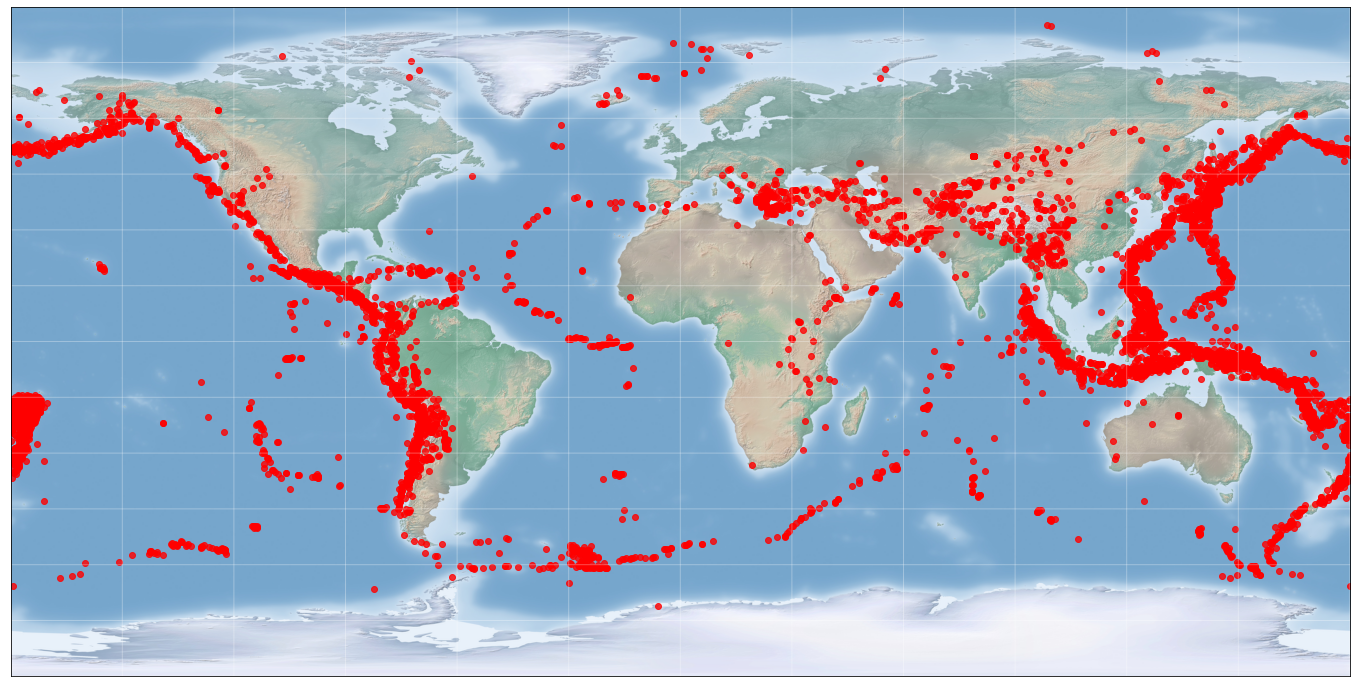

In [73]:
fig = plt.figure(figsize=(24, 18), edgecolor='w')
m = Basemap(projection='cyl', resolution=None,
            llcrnrlat=-90, urcrnrlat=90,
            llcrnrlon=-180, urcrnrlon=180, )
m.scatter(datos_lon, datos_lat, latlon=True, c='red', alpha=0.8)
draw_map(m);

In [74]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

In [75]:
#df=pd.DataFrame({'X': range(1,101), 'Y': np.random.randn(100)*15+range(1,101), 'Z': (np.random.randn(100)*15+range(1,101))*2 })

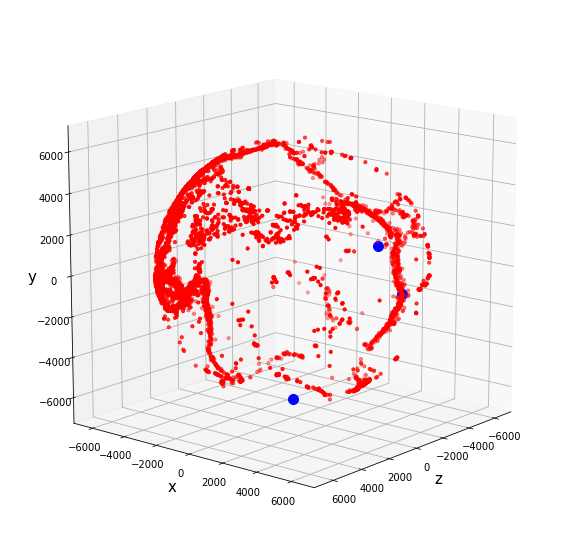

In [76]:
# plot
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
ax.set_xlabel('z', fontsize=15)
ax.set_ylabel('x', fontsize=15)
ax.set_zlabel('y', fontsize=15)
# Este gráfico funciona con las columnas ya creadas x, y, z:
ax.scatter(sismos['z'], sismos['x'], sismos['y'], s=10, c='red')

# Sección de America del Sur en el Globo:
ax.scatter(0, radio_ecuador, 0, s=100, c='blue')
ax.scatter(-radio_ecuador, 0, 0, s=100, c='blue')
ax.scatter(0, 0, -radio_polos, s=100, c='blue')

ax.view_init(15, 40)
plt.show()

Recuperemos Distancia al Centro, Latitud y Longitud a partir de las posiciones tridimensionales X, Y y Z:

**CONSIGNA**: 
Dados dos arrays, encontrar una forma de determinar en qué medida se parecen según los valores que contienen

**Pistas para la implementación**

1. En modelos de regresión lineal, una forma que medir la exactitud de las prediciones del modelo, es atravez de la tecnica de Error Absoluto Medio o MAE por sus siglas en Ingles.


In [88]:
N = 1000
a1 = np.random.randint(3, size=N)
a2 = np.random.randint(3, size=N)

In [89]:
#Probamos con el error absoluto medio:
def calculo_MAE(a1, a2):
    dif = 0
    if a1.size != a2.size:
        return 'Los arrays son de diferentes tamaños'
    else:
        #Agregar código aquí
    return dif / a1.size

In [91]:
#Pobamos con el error cuadrático medio
def calculo_RMSE(a1, a2):
    dif = 0
    if a1.size != a2.size:
        return 'Los arrays son de diferentes tamaños'
    else:
        #Agregar código aquí
    return math.sqrt(dif / a1.size)

Para pensar: ¿Hay una forma mejor de hacerlo? ¿Qué ventajas podría tener?

## Ejercicio 3

**CONSIGNA**: 

El juego de la vida es un juego de cero jugadores, lo que significa que una vez que indicas el estado inicial, te olvidas de participar más y te conviertes en un mero espectador. Este autómata va mostrando su estado a través de una malla plana "infinita" formada por cuadrados denominados células. 
Cada célula tiene 8 células vecinas, y cada una de las células tiene dos estados, "viva" ("encendida") o muertas ("apagada"). A partir de ahí el estado evoluciona en una especie de turnos de acuerdo a dos reglas:

1-Una célula muerta con exactamente 3 células vecinas vivas "nace" (es decir, al turno siguiente estará viva)

2-Una célula viva con 2 o 3 células vecinas vivas sigue viva, pero en otro caso muere (por "soledad" o "superpoblación")

Hay numerosos patrones de células que se pueden dar en el juego de la vida. Los osciladores, por ejemplo, acaban volviendo a su estado inicial tras un número finito de generaciones o turnos (su "período"), mientras que las vidas estáticas son patrones que no cambian nunca, o en otras palabras: son osciladores de período 1. Hay "naves espaciales" que cambian de posición tras cada generación, "matusalenes" que tardan muchísimos turnos en estabilizarse y multitud de variantes de todos ellos.

Con el juego de la vida se puede construir una estructura que actúe como una máquina de estados finitos, y que tendría el mismo comportamiento y potencia que una máquina de Turing.

**En esta ejercitación, es necesario completar el código en la funcion "paso()" donde se aplican las reglas de evolución del juego**

Enlaces interesantes:

https://playgameoflife.com/

https://www.xataka.com/historia-tecnologica/mitico-juego-vida-matematico-john-conway-sigue-siendo-uno-problemas-clasicos-programacion-50-anos-despues

https://seguridadpy.info/2018/06/al-principio-steve-jobs-y-steve-wozniak-no-sabian-vender-el-fracaso-de-la-primera-demo-del-apple-ii-y-el-juego-de-la-vida-de-conway/

In [93]:
from time import sleep
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib import animation
from matplotlib.animation import FuncAnimation

In [94]:
# Parámetros del problema
GENERACIONES = 30
N = 15
M = 15

In [95]:
#Esta funcion determina el estado siguiente del tablero
def paso(b):
    i_ar = 0
    i_ab = 0
    j_iz = 0
    j_de = 0
    buffer_b = b.copy()
    
    for i in range(N):
        for j in range(M):
            
            estado_celula = buffer_b[i,j]
            
            #Agregar codigo en esta sección:


            #Fin codigo agregado.
            
            b[i,j] = estado_celula   
    return b

In [101]:
# Construimos el tablero
tablero = np.zeros((N, M), dtype=int)
g = 0 

In [102]:
# Añadimos una nave
tablero[4, 5] = 1
tablero[5, 4] = 1
tablero[6, 4:7] = 1
tablero[9, 5:7] = 1
tablero[10, 4] = 1
tablero[10, 6] = 1
tablero[11, 6] = 1

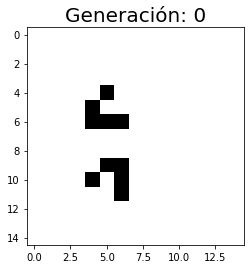

In [103]:
# Creamos la figura
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(111)
ax.set_title("Generación: {}".format(g), fontsize=20)
#ax.axis('off')
b = tablero
imagen = ax.imshow(b, interpolation="none", cmap=cm.gray_r)

In [99]:
def update(i):
    im_normed = paso(b)
    ax.imshow(im_normed)
    ax.set_title("Generación: {}".format(i), fontsize=20)

In [100]:
anim = FuncAnimation(fig, update, frames=np.arange(0, GENERACIONES), interval=50)
anim.save('Juego_Vida.mp4', fps=10)

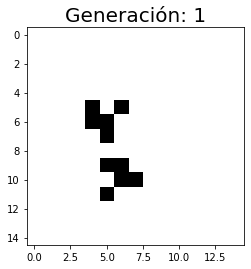

In [104]:
# Tambien, podemos ejecutar esta celda, y ver los cambios en el tablero para probar el codigo
g = g + 1
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(111)
ax.set_title("Generación: {}".format(g), fontsize=20)
#ax.axis('off')
b = paso(b)
imagen = ax.imshow(b, interpolation="none", cmap=cm.gray_r)